In [54]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam # optimizer
from tensorflow.keras.callbacks import Callback, EarlyStopping
from PIL import Image

# Fix every source of randomness so results can be reproduced
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [55]:
from collections import Counter

DATA_DIR = "split"            
SPLITS = {"train": "train", "val": "validation", "test": "test"}
IMG_EXT = (".pgm")

for split, folder in SPLITS.items():
    sizes, modes, skipped = Counter(), Counter(), []
    for root, _, files in os.walk(os.path.join(DATA_DIR, folder)):
        for f in files:
            if not f.lower().endswith(IMG_EXT):
                skipped.append(f)                  
                continue
            with Image.open(os.path.join(root, f)) as img:
                sizes[img.size] += 1               # PIL size is (width, height)
                modes[img.mode] += 1               # 'L' = grayscale, 'RGB' = colour

    print(f"------------- {split} ({sum(sizes.values())} images) -------------")
    for (w, h), n in sizes.most_common():
        print(f"  {w} x {h} (W x H): {n} images")
    print(f"  colour modes: {dict(modes)}")
    if skipped:
        print(f"  skipped {len(skipped)} non-image files, e.g. {skipped[:3]}")

------------- train (436 images) -------------
  64 x 60 (W x H): 436 images
  colour modes: {'L': 436}
------------- val (93 images) -------------
  64 x 60 (W x H): 93 images
  colour modes: {'L': 93}
------------- test (95 images) -------------
  64 x 60 (W x H): 95 images
  colour modes: {'L': 95}


In [56]:
# ---- Settings ----
IMG_H, IMG_W = 60, 64              # height, width of every image
CLASSES = ["left", "right", "straight", "up"]
NUM_CLASSES = len(CLASSES)

def load_split(folder):
    #Load every image in a folder.

    X, y = [], []
    for root, _, files in os.walk(folder):
        for f in sorted(files):
            if not f.lower().endswith(IMG_EXT):
                continue                                      # skips .bad and other files
            img = np.asarray(Image.open(os.path.join(root, f)).convert("L"), dtype=np.float32)
            if img.shape != (IMG_H, IMG_W):                   # numpy shape is (height, width)
                raise ValueError(f"{f} has shape {img.shape}, expected {(IMG_H, IMG_W)}")
            X.append(img / 255.0)                             # scale pixels to [0, 1]
            y.append(CLASSES.index(os.path.splitext(f)[0].split("_")[1]))
    return np.stack(X)[..., None], np.array(y)               

X_train, y_train = load_split(os.path.join(DATA_DIR, SPLITS["train"]))
X_val,   y_val   = load_split(os.path.join(DATA_DIR, SPLITS["val"]))
X_test,  y_test  = load_split(os.path.join(DATA_DIR, SPLITS["test"]))

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Train: (436, 60, 64, 1)  Val: (93, 60, 64, 1)  Test: (95, 60, 64, 1)


split  total             left            right         straight               up
train    436     105 ( 24.1%)     113 ( 25.9%)     109 ( 25.0%)     109 ( 25.0%)
val       93      25 ( 26.9%)      23 ( 24.7%)      26 ( 28.0%)      19 ( 20.4%)
test      95      27 ( 28.4%)      19 ( 20.0%)      21 ( 22.1%)      28 ( 29.5%)


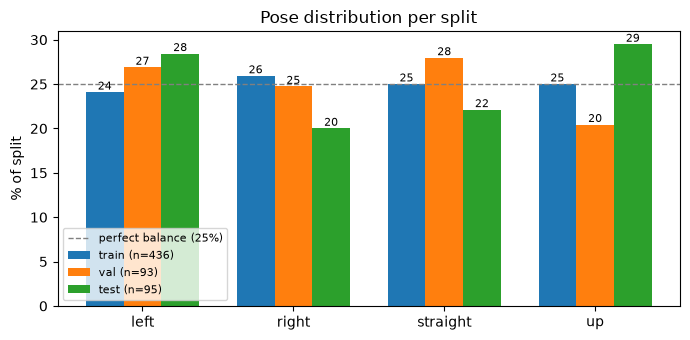

In [57]:
splits = {"train": y_train, "val": y_val, "test": y_test}

# Table of counts and percentages per pose
print(f"{'split':6s} {'total':>5s}  " + "  ".join(f"{c:>15s}" for c in CLASSES))
for name, y in splits.items():
    counts = np.bincount(y, minlength=NUM_CLASSES)
    pct = 100 * counts / counts.sum()
    cells = "  ".join(f"{n:4d} ({p:5.1f}%)".rjust(15) for n, p in zip(counts, pct))
    print(f"{name:6s} {len(y):5d}  {cells}")

# Grouped bar chart of the percentages
x = np.arange(NUM_CLASSES)
width = 0.25
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, (name, y) in enumerate(splits.items()):
    pct = 100 * np.bincount(y, minlength=NUM_CLASSES) / len(y)
    bars = ax.bar(x + (k - 1) * width, pct, width, label=f"{name} (n={len(y)})")
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.axhline(25, color="gray", linestyle="--", linewidth=1, label="perfect balance (25%)")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel("% of split")
ax.set_title("Pose distribution per split")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [58]:
# EpochTimer callback to record how long each epoch takes
class EpochTimer(Callback):
    # Records how long each epoch takes.
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

In [59]:
# building model A

def build_model_A():
    keras.utils.set_random_seed(SEED)   # same initial weights on every call
    return models.Sequential([
        layers.Input(shape=(60, 64, 1)),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),

        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(4, activation="softmax"),
    ], name="Model_A")

def train(optimizer, epochs, batch_size=32, verbose=0):
    model = build_model_A()
    model.compile(optimizer=optimizer,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    timer = EpochTimer()
    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size,
                        callbacks=[timer], verbose=verbose)
    return model, history, timer

build_model_A().summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 60, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 30, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 15, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 7, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 248,772 (971.77 KB)

 Trainable params: 248,772 (971.77 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
EPOCHS = 100

model_A, history_A, timer_A = train(Adam(1e-3), epochs=EPOCHS, verbose=1)
time_per_epoch_A = np.mean(timer_A.times[1:])   # skip epoch 1 (one-off setup)
print(f"Average time per epoch: {time_per_epoch_A:.3f} s")
model_A.summary()

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.2202 - loss: 1.3904 - val_accuracy: 0.2796 - val_loss: 1.3855
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.2638 - loss: 1.3863 - val_accuracy: 0.2796 - val_loss: 1.3859
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.2615 - loss: 1.3854 - val_accuracy: 0.2473 - val_loss: 1.3856
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.2385 - loss: 1.3866 - val_accuracy: 0.2473 - val_loss: 1.3855
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.2454 - loss: 1.3858 - val_accuracy: 0.2473 - val_loss: 1.3853
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.2683 - loss: 1.3840 - val_accuracy: 0.2473 - val_loss: 1.3798
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.2752 - loss: 1.3773 - val_accuracy: 0.2688 - val_loss: 1.3650
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.3417 - loss: 1.3595 - val_accuracy: 0.

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_40 (Conv2D)              │ (None, 60, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 30, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 15, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 7, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 746,318 (2.85 MB)

 Trainable params: 248,772 (971.77 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 497,546 (1.90 MB)

In [61]:
# parameter calculation

trainable     = sum(int(np.prod(w.shape)) for w in model_A.trainable_weights)
non_trainable = sum(int(np.prod(w.shape)) for w in model_A.non_trainable_weights)
total = trainable + non_trainable

print(f"Trainable params:     {trainable:,}")
print(f"Non-trainable params: {non_trainable:,}")
print(f"Total params:         {total:,}")

Trainable params:     248,772
Non-trainable params: 0
Total params:         248,772


In [62]:
def count_macs(model):
    # Multiply-accumulates of Conv2D and Dense layers.
    total = 0
    for layer in model.layers:
        if isinstance(layer, layers.Conv2D):
            _, h, w, c_out = layer.output.shape          # output height, width, channels
            kh, kw = layer.kernel_size
            c_in = layer.input.shape[-1]
            macs = h * w * kh * kw * c_in * c_out        # one k*k*C_in dot product per output value
        elif isinstance(layer, layers.Dense):
            macs = layer.input.shape[-1] * layer.units
        else:
            continue
        total += macs
        print(f"{layer.name:8s} {macs:>12,}")
    print(f"{'TOTAL':8s} {total:>12,}  (~{total / 1e6:.2f} M MACs per image)")
    return total

macs_a = count_macs(model_A)

conv2d_40    1,105,920
conv2d_41   17,694,720
conv2d_42   17,694,720
conv2d_43    8,257,536
dense_20        8,192
dense_21          256
TOTAL      44,761,344  (~44.76 M MACs per image)


In [63]:
model_A.save("model_A.keras", include_optimizer=False)
size_kb_A = os.path.getsize("model_A.keras") / 1024
print(f"Model A size on disk: {size_kb_A:.1f} KB")

Model A size on disk: 2967.1 KB


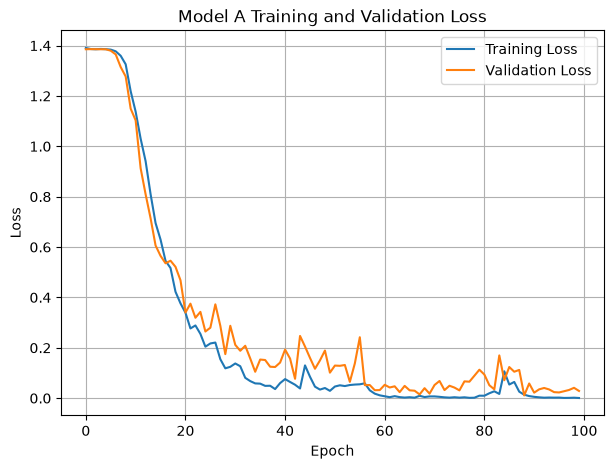

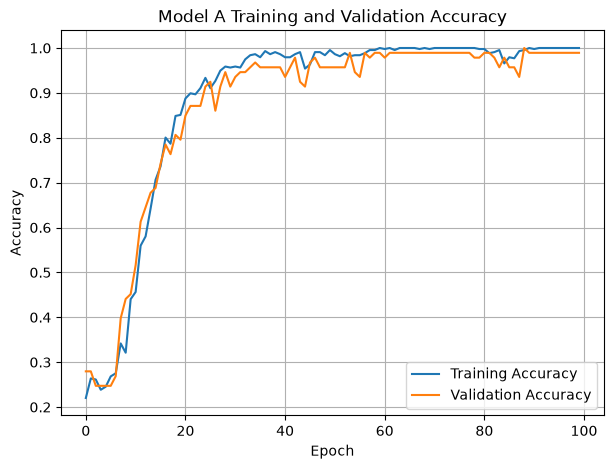

In [64]:
# plot model A training and validation loss and accuracy

plt.figure(figsize=(7,5))
plt.plot(history_A.history["loss"], label="Training Loss")
plt.plot(history_A.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(history_A.history["accuracy"], label="Training Accuracy")
plt.plot(history_A.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9789 - loss: 0.0534
Test Accuracy: 97.89%
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


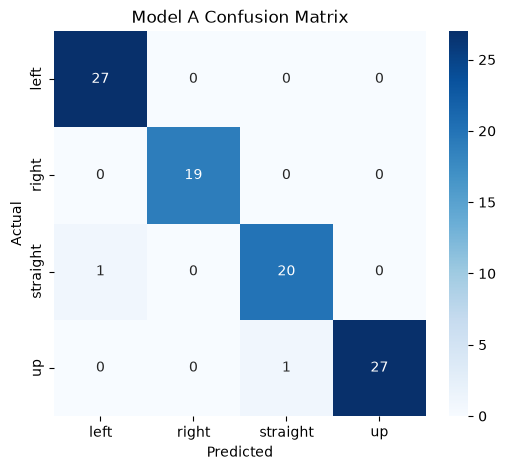

              precision    recall  f1-score   support

        left     0.9643    1.0000    0.9818        27
       right     1.0000    1.0000    1.0000        19
    straight     0.9524    0.9524    0.9524        21
          up     1.0000    0.9643    0.9818        28

    accuracy                         0.9789        95
   macro avg     0.9792    0.9792    0.9790        95
weighted avg     0.9793    0.9789    0.9789        95



In [65]:
# plot confusion matrix and classification report for model A

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_loss, test_accuracy = model_A.evaluate(X_test, y_test, verbose=1)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

y_pred = np.argmax(model_A.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model A Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))

In [ ]:
from tensorflow.keras.optimizers import SGD

optimizers = {
    "Adam (lr=1e-3)":               lambda: Adam(learning_rate=1e-3),
    "SGD (lr=5e-2)":                lambda: SGD(learning_rate=5e-2),
    "SGD + momentum 0.9 (lr=5e-2)": lambda: SGD(learning_rate=5e-2, momentum=0.9),
}

opt_results = {}
for name, make_opt in optimizers.items():
    print(f"Training with {name} ...")
    model, history, timer = train(make_opt(), epochs=EPOCHS)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    opt_results[name] = {"history": history.history,
                         "test_acc": test_acc,
                         "sec_per_epoch": np.mean(timer.times[1:])}

Training with Adam (lr=1e-3) ...
Training with SGD (lr=1e-2) ...
Training with SGD + momentum 0.9 (lr=1e-2) ...


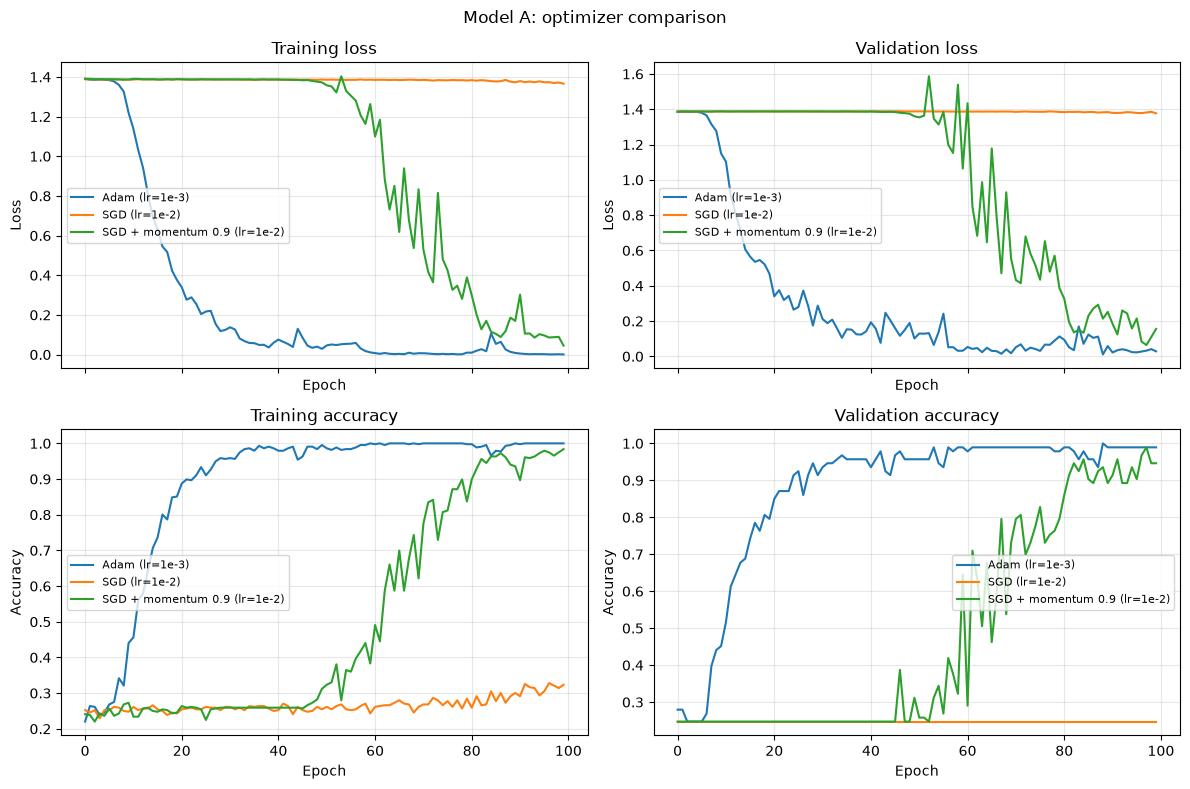

Optimizer                        best val acc  epoch to 90% val  test acc  s/epoch
Adam (lr=1e-3)                          1.000                25     0.979    1.375
SGD (lr=1e-2)                           0.247             never     0.200    0.663
SGD + momentum 0.9 (lr=1e-2)            0.989                82     0.926    0.537


In [72]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for name, r in opt_results.items():
    h = r["history"]
    axes[0, 0].plot(h["loss"], label=name)
    axes[0, 1].plot(h["val_loss"], label=name)
    axes[1, 0].plot(h["accuracy"], label=name)
    axes[1, 1].plot(h["val_accuracy"], label=name)

titles = [["Training loss", "Validation loss"],
          ["Training accuracy", "Validation accuracy"]]
for i in range(2):
    for j in range(2):
        axes[i, j].set_title(titles[i][j])
        axes[i, j].set_xlabel("Epoch")
        axes[i, j].set_ylabel("Loss" if i == 0 else "Accuracy")
        axes[i, j].grid(alpha=0.3)
        axes[i, j].legend(fontsize=8)
plt.suptitle("Model A: optimizer comparison")
plt.tight_layout()
plt.show()

# Summary table for the report
print(f"{'Optimizer':32s} {'best val acc':>12s} {'epoch to 90% val':>17s} {'test acc':>9s} {'s/epoch':>8s}")
for name, r in opt_results.items():
    va = np.array(r["history"]["val_accuracy"])
    hit = np.argmax(va >= 0.90) + 1 if (va >= 0.90).any() else "never"
    print(f"{name:32s} {va.max():12.3f} {str(hit):>17s} {r['test_acc']:9.3f} {r['sec_per_epoch']:8.3f}")

lr=0.01, m=0.9               best val acc 0.806   epoch to 90%: never
lr=0.03, m=0.9               best val acc 0.548   epoch to 90%: never
lr=0.05, m=0.9               best val acc 0.989   epoch to 90%: 82
lr=0.01, m=0.95              best val acc 0.882   epoch to 90%: never
lr=0.03, m=0.9, Nesterov     best val acc 0.925   epoch to 90%: 100


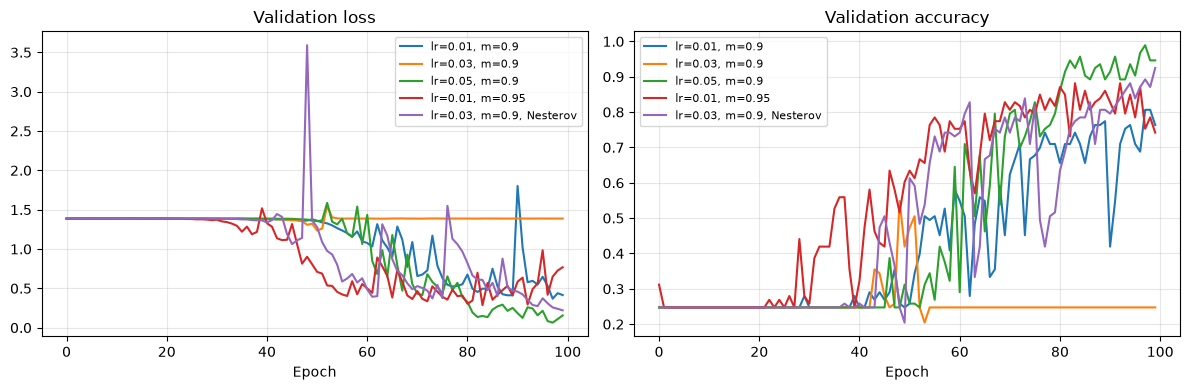

In [ ]:
momentum_runs = {}
for m in [0.0, 0.5, 0.9, 0.99]:
    _, h, _ = train(SGD(learning_rate=5e-2, momentum=m), epochs=EPOCHS)
    momentum_runs[m] = h.history

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for m, h in momentum_runs.items():
    ax1.plot(h["val_loss"], label=f"momentum={m}")
    ax2.plot(h["val_accuracy"], label=f"momentum={m}")
ax1.set_title("Validation loss"); ax2.set_title("Validation accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()